# Data Understanding — Insurance Complaints (Phase 1)

**Mục tiêu:** làm rõ 13 câu hỏi Gate 1 từ dữ liệu đã profile, phân biệt điều dữ liệu trả lời được với quyết định nghiệp vụ chưa chốt.

**Nguồn (chỉ đọc):** `data/insurance_complain.xlsx` (1.860.240 bytes, SHA-256 `3ace0642…159032`), `data/Đề bài.docx` (SHA-256 `bcbc2d39…27597c`). Hash khớp baseline Plan/PLAN.md §2; setup kiểm lại.

**Grain:** 1 complaint = 1 dòng `Complains Data` (13.846); 1 sự kiện = 1 dòng `Status History Data` (11.558). Đã kiểm: 0 trùng khóa, 0 orphan FK.

**Định nghĩa tạm thời (chờ Gate 1):** as-of ứng viên = ngày complain max (2020-05-14); open = OUTSTANDING/IN PROGRESS; completed cohort = cặp ngày hợp lệ delta ≥ 0 (gồm 0 ngày); SAT rate = SAT/(SAT+NSA).

**Giới hạn:** không kết luận nguyên nhân; không đặt target/currency; không in tên/ngày sinh/row cá nhân — chỉ tổng hợp và metadata.

In [1]:
%matplotlib inline
import hashlib, json, os
from collections import Counter, defaultdict
from datetime import date, datetime
import openpyxl
import pandas as pd
import matplotlib.pyplot as plt

CWD = os.getcwd()
ROOT = CWD if os.path.isdir(os.path.join(CWD, 'data')) else os.path.dirname(CWD)
XLSX = os.path.join(ROOT, 'data', 'insurance_complain.xlsx')
FIG = os.path.join(ROOT, 'reports', 'profile', 'figures')
BASELINE_SHA = '3ace06421c1a8d146b0bfa6b9f08a2ae367bf32ead212182cb84b3d5af159032'
CUTOFF = date(2020, 5, 14)   # ngay tham chieu phan tich duoc chon, KHONG phai snapshot xac nhan
os.makedirs(FIG, exist_ok=True)
PROF = json.load(open(os.path.join(ROOT, 'reports', 'profile', 'profile_phase1.json'), encoding='utf-8'))
INV = json.load(open(os.path.join(ROOT, 'reports', 'profile', 'investigation_phase1.json'), encoding='utf-8'))
REP = json.load(open(os.path.join(ROOT, 'reports', 'profile', 'repair_r01_r06_cohorts.json'), encoding='utf-8'))

h = hashlib.sha256(open(XLSX, 'rb').read()).hexdigest()
assert h == BASELINE_SHA, 'NGUON LECH: %s != %s' % (h, BASELINE_SHA)

def blank(v):
    return v is None or (isinstance(v, str) and not v.strip())

def named(sheet):
    """Doc sheet read-only, tra list dict theo TEN COT. Doc dung 1 lan, khong tieu lai iterator."""
    wb = openpyxl.load_workbook(XLSX, read_only=True, data_only=True)
    it = wb[sheet].iter_rows(values_only=True)
    hdr = [None if x is None else str(x).strip() for x in next(it)]
    cols = [c for c in hdr if c]
    out = [{c: r[i] for i, c in enumerate(hdr) if c}
           for r in it if not all(blank(v) for v in r)]
    wb.close()
    return out

CUST = named('Customers')
BIRTH = {c['CustomerID']: c['BirthDate'] for c in CUST}
COMPL = named('Complains Data')
COMP_BY_ID = {c['ID']: c for c in COMPL}
STATUS = {1.0: 'OUTSTANDING', 2.0: 'NEW', 3.0: 'IN PROGRESS', 4.0: 'ASSIGNED TO',
          5.0: 'RESOLVED', 6.0: 'PENDING', 9.0: 'CLOSED'}
N_COMPL = len(COMPL)
print('nguon khop baseline | complaints:', N_COMPL, '| customers:', len(CUST))
print('profile asserts:', PROF['summary']['assertions_total'], 'failed:', PROF['summary']['assertions_failed'])

def tab(rws, cols):
    return pd.DataFrame(rws, columns=cols)

# B03: history <= CUTOFF cho TOAN population, tach tie / thieu
EV = defaultdict(list)
N_AFTER = 0
for e in named('Status History Data'):
    sd = e['StatusDate']
    if not isinstance(sd, (datetime, date)):
        continue
    if sd.date() > CUTOFF:
        N_AFTER += 1
        continue
    EV[e['ComplaintID']].append((sd, e['ComplaintStatusID']))
for v in EV.values():
    v.sort()

def latest(cid):
    """('unambiguous'|'ambiguous'|'missing', status) tai cutoff. Khong chon tie-break."""
    ev = EV.get(cid)
    if not ev:
        return 'missing', None
    mx = ev[-1][0]
    sts = {s for d, s in ev if d == mx}
    return ('ambiguous' if len(sts) > 1 else 'unambiguous'), sorted(sts)

print('events sau cutoff:', N_AFTER, '| complaints co history <= cutoff:', len(EV))


nguon khop baseline | complaints: 13846 | customers: 12305
profile asserts: 25 failed: 0


events sau cutoff: 1 | complaints co history <= cutoff: 4351


**Setup đã làm gì:** import stdlib + thư viện có sẵn; tự tìm project root (chạy được từ root hoặc `notebooks/`); nạp 3 JSON đã kiểm chứng thay vì chạy lại pipeline; xác minh hash nguồn; helper `named(sheet)` đọc read-only trả list dict **theo tên cột** và `tab()` in bảng. Không cài thêm gì.

## Q1 — 50 ô CompletionDate chữ "NULL" là gì?

Câu hỏi gốc: CompletionDate null xử lý thế nào; 50 complaint mở có thực sự thiếu ngày hoàn tất?

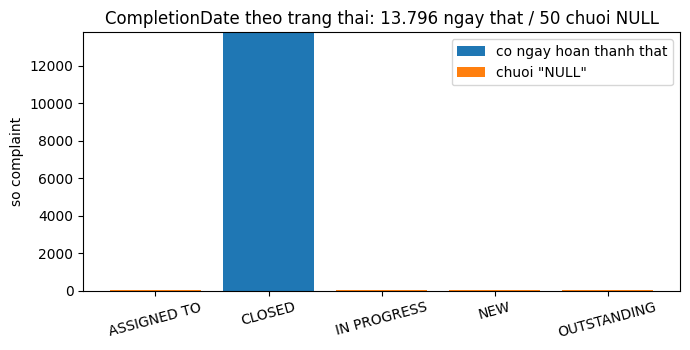

In [2]:
svc = PROF['dates']['status_vs_completion']
kinds = [(k.split('|')[0], k.split('|')[1], v) for k, v in svc['completion_kind_by_status'].items()]
tab(sorted(kinds), ['status', 'completion_kind', 'n'])
sts = sorted({k.split('|')[0] for k in svc['completion_kind_by_status']})
kd = [(k.split('|')[0], k.split('|')[1], v) for k, v in svc['completion_kind_by_status'].items()]
real = [sum(v for s, kind, v in kd if s == st and kind == 'real_date') for st in sts]
nulls = [sum(v for s, kind, v in kd if s == st and kind == 'literal_NULL') for st in sts]
plt.figure(figsize=(7, 3.6))
plt.bar(sts, real, label='co ngay hoan thanh that')
plt.bar(sts, nulls, bottom=real, label='chuoi "NULL"')
plt.title('CompletionDate theo trang thai: 13.796 ngay that / 50 chuoi NULL')
plt.ylabel('so complaint'); plt.xticks(rotation=15); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q01_completion_kind.png'), dpi=100)
plt.show()


**Quan sát:** 13.796 `CLOSED` đều có ngày thật; 50 complaint chưa đóng (`ASSIGNED TO` 16, `NEW` 13, `IN PROGRESS` 13, `OUTSTANDING` 8) đều mang chữ `"NULL"` — không ô nào parse được thành ngày. Biểu đồ cho thấy cột ngày thật không lẫn vào bất kỳ trạng thái mở nào. Con số "21 open có completion" ở revision cũ là artefact do đếm chuỗi `"NULL"` là có giá trị; revision này `open_status_with_real_completion_date = 0`.

**Ý nghĩa:** CompletionDate đang gánh hai vai — ngày hoàn tất (13.796) và một giá trị chữ ở nhóm chưa đóng. Mọi phép tính thời gian phải lọc chỉ ngày thật.

**Giới hạn:** `"NULL"` **chưa được chứng minh là cờ nghiệp vụ** "chưa hoàn tất". Dữ liệu chỉ cho thấy 50 ô đó không phải ngày hợp lệ và trùng khớp với nhóm chưa đóng; có thể là ký hiệu dự kiến dùng chưa hoàn thiện. Cần người dùng xác nhận trước khi Phase 2 gán nghĩa. **Phân loại:** số đếm ✔ trả lời được · quy tắc xử lý ✋ cần chốt.


## Q2 — 1.899 complaint "0 ngày" giữ hay loại?

Câu hỏi gốc: cohort tính thời gian xử lý gồm những ai; median/mean có đại diện?

           cohort     n  min  median      mean  p90  max
baseline delta>=0 13796    0     7.0 12.849087 35.0  222
      chi delta>0 11897    1     8.0 14.900059 38.0  222
so ca 0 ngay trong baseline: 1899


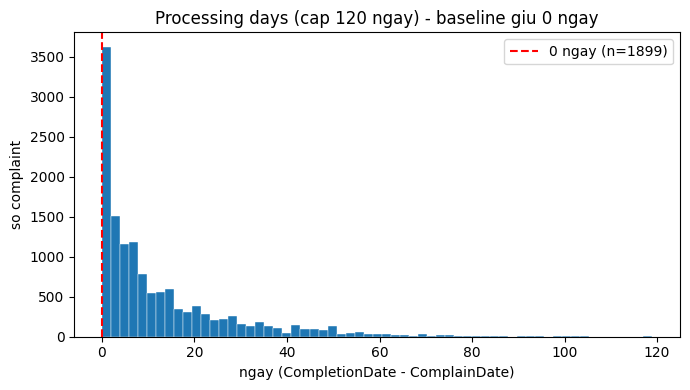

In [3]:
days = []
for c in COMPL:
    cd, cpd = c['ComplainDate'], c['CompletionDate']
    if isinstance(cd, (datetime, date)) and isinstance(cpd, (datetime, date)):
        d = (cpd - cd).days
        if d >= 0:
            days.append(d)
coh = PROF['dates']['completed_cohort_days']
pos = PROF['dates']['positive_only_days']
print(tab([['baseline delta>=0', coh['n'], coh['min'], coh['median'], coh['mean'], coh['p90'], coh['max']],
           ['chi delta>0', pos['n'], pos['min'], pos['median'], pos['mean'], pos['p90'], pos['max']]],
          ['cohort', 'n', 'min', 'median', 'mean', 'p90', 'max']).to_string(index=False))
print('so ca 0 ngay trong baseline:', sum(1 for d in days if d == 0))
plt.figure(figsize=(7, 4))
plt.hist([d for d in days if d <= 120], bins=61, edgecolor='white', linewidth=0.3)
plt.axvline(0, color='red', linestyle='--', label='0 ngay (n=%d)' % sum(1 for d in days if d == 0))
plt.title('Processing days (cap 120 ngay) - baseline giu 0 ngay')
plt.xlabel('ngay (CompletionDate - ComplainDate)'); plt.ylabel('so complaint')
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q02_processing_days.png'), dpi=100)
plt.show()


**Quan sát:** baseline gồm 0 ngày: n = 13.796, min 0, median 7,0, mean 12,85, p90 35, max 222. Cohort dương thuần: n = 11.897, median 8,0, mean 14,90. Biểu đồ cho thấy cột 0 ngày vượt trội (1.899 ca, toàn `CLOSED`) rồi phân phối lệch phải tới 222 ngày.

**Ý nghĩa:** loại 0 ngày làm median tăng 1 ngày và mean tăng ~2 ngày. Baseline giữ 0 ngày vì mọi ca đó đều `CLOSED`; positive-only tách riêng để so sánh, **không phải quy tắc đã được duyệt loại 0 ngày**.

**Giới hạn:** chưa biết 0 ngày là xử lý trong ngày hay ghi ngày nhận = ngày đóng. Hai cách đọc khác nhau về nghiệp vụ nên **giữ cả hai cohort** cho tới khi người dùng chốt. **Phân loại:** số ✔ đã đối chiếu độc lập · nghiệp vụ 0 ngày ✋ cần chốt.


## Q3 — Ngày as-of nào dùng được?

Câu hỏi gốc: chốt mốc snapshot để tính backlog/tuổi.

                              moc    gia_tri
              cutoff (tham chieu) 2020-05-14
                 max ComplainDate 2020-05-14
               max CompletionDate 2020-05-14
                   max StatusDate 2020-05-15
events history > cutoff (da loai)          1
                     so complaint      13846


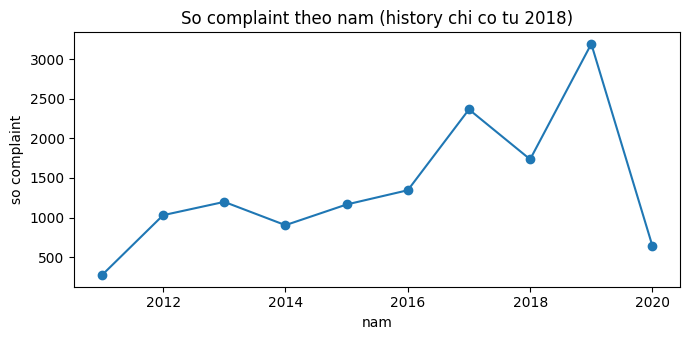

In [4]:
sd = PROF['complaints']['status_distribution']
print(tab([['cutoff (tham chieu)', CUTOFF], ['max ComplainDate', PROF['dates']['complain_date_max'][:10]],
           ['max CompletionDate', PROF['dates']['completion_date_max'][:10]],
           ['max StatusDate', PROF['status_history']['statusdate_max'][:10]],
           ['events history > cutoff (da loai)', N_AFTER], ['so complaint', N_COMPL]],
          ['moc', 'gia_tri']).to_string(index=False))
yr = Counter(c['ComplainDate'].year for c in COMPL if isinstance(c['ComplainDate'], (datetime, date)))
plt.figure(figsize=(7, 3.5))
plt.plot(sorted(yr), [yr[y] for y in sorted(yr)], marker='o')
plt.title('So complaint theo nam (history chi co tu 2018)')
plt.xlabel('nam'); plt.ylabel('so complaint'); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q03_trend.png'), dpi=100)
plt.show()


**Quan sát:** `CUTOFF = 14/05/2020` là **ngày tham chiếu phân tích do code chọn** (max `ComplainDate` = max `CompletionDate` = 14/05/2020). `max StatusDate` = 15/05/2020, nên có **1 event nằm sau cutoff** và bị loại có chủ đích trong mọi phép tính lịch sử. Biểu đồ cho thấy complaint từ 2011 tới đỉnh 2019.

**Ý nghĩa:** as-of (ngày tham chiếu) và snapshot date (ngày trạng thái được chụp) là hai khái niệm khác nhau; nguồn này **không công bố** ngày snapshot. Khoảng trống lịch sử 2011–2017 là **hiện tượng quan sát được**, không phải nguyên nhân đã chứng minh.

**Giới hạn:** quét toàn văn đề và metadata workbook không tìm thấy quy định ngày snapshot; không có provenance nguồn xác nhận. Không tự đổi sang 15/05. **Phân loại:** ~ trả lời một phần; ngày snapshot chưa chốt ✋.


## Q4 — Backlog > 30 ngày còn ý nghĩa không?

Câu hỏi gốc: có bao nhiêu case tồn quá 30 ngày ở các trạng thái mục tiêu.

                             chi_so  n
                 OUTSTANDING (fact)  8
                 IN PROGRESS (fact) 13
                   tong cohort fact 21
    trong do complaint age >30 ngay  2
days since last observed event: max 28
 days since last observed event >30  0
        latest ambiguous tai cutoff  4


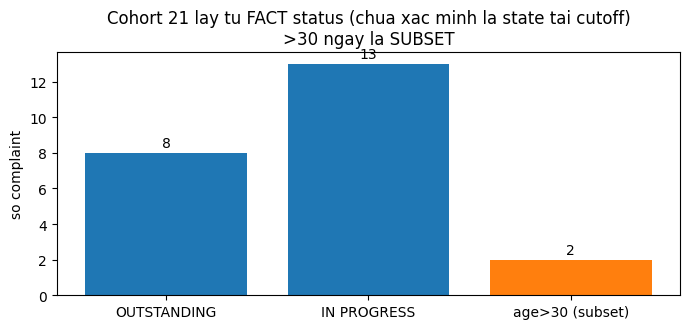

In [5]:
sd = PROF['complaints']['status_distribution']
TGT = [c for c in COMPL if c['ComplainStatusID'] in (1.0, 3.0)]
NONCLOSED = [c for c in COMPL if c['ComplainStatusID'] != 9.0]
age_gt30 = sum(1 for c in TGT if isinstance(c['ComplainDate'], (datetime, date))
               and (CUTOFF - c['ComplainDate'].date()).days > 30)
dsle = [(CUTOFF - EV[c['ID']][-1][0].date()).days for c in TGT if c['ID'] in EV]
amb_t = sum(1 for c in TGT if latest(c['ID'])[0] == 'ambiguous')
print(tab([['OUTSTANDING (fact)', sd['OUTSTANDING']], ['IN PROGRESS (fact)', sd['IN PROGRESS']],
           ['tong cohort fact', len(TGT)], ['trong do complaint age >30 ngay', age_gt30],
           ['days since last observed event: max', max(dsle) if dsle else None],
           ['days since last observed event >30', sum(1 for x in dsle if x > 30)],
           ['latest ambiguous tai cutoff', amb_t]],
          ['chi_so', 'n']).to_string(index=False))
plt.figure(figsize=(7, 3.4))
lab = ['OUTSTANDING', 'IN PROGRESS', 'age>30 (subset)']
val = [sd['OUTSTANDING'], sd['IN PROGRESS'], age_gt30]
plt.bar(lab, val, color=['tab:blue', 'tab:blue', 'tab:orange'])
for x, y in enumerate(val):
    plt.text(x, y + 0.3, str(y), ha='center')
plt.title('Cohort 21 lay tu FACT status (chua xac minh la state tai cutoff)\n>30 ngay la SUBSET')
plt.ylabel('so complaint'); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q04_backlog.png'), dpi=100)
plt.show()


**Quan sát:** cohort 21 được lấy từ **trạng thái fact hiện có** (`OUTSTANDING` 8, `IN PROGRESS` 13) — đây **chưa được xác minh là trạng thái lịch sử tại cutoff**, vì có 4 ca latest ambiguous và nguồn không công bố snapshot. Trong 21 ca: **2 ca có complaint age > 30 ngày**; **days since last observed event** (`cutoff − ngày event cuối ≤ cutoff`) có max 28 ngày và **0 ca > 30**. Đại lượng thứ hai **không phải time-in-status** và không phải KPI.

**Ý nghĩa:** ">30 ngày" là **subset của 21**, không phải nhóm thứ ba. Với khoảng cách giữa tuổi complaint và số ngày kể từ event cuối, gộp hai khái niệm sẽ ra kết luận sai.

**Giới hạn:** chưa tái dựng được cohort as-of đúng vì thiếu quy tắc tie và ngày snapshot; `days since last observed event` chỉ là proxy quan sát. Câu 4 của đề về backlog >30 ngày **chưa đủ bằng chứng**. **Phân loại:** ✔ quan sát · ✋ KPI cần nguồn và quy tắc.


## Q5 — SAT 89,33% có dùng được không?

Câu hỏi gốc: coverage đánh giá và cách đọc tỷ lệ hài lòng.

    chi_so  gia_tri
SAT CLOSED  6856.00
   SAT NEW    11.00
  SAT tong  6867.00
  NSA tong   820.00
  N/A tong  6159.00
coverage %    55.52
     status  SAT  NSA  N/A  tong
ASSIGNED TO    0    0   16    16
     CLOSED 6856  820 6120 13796
IN PROGRESS    0    0   13    13
        NEW   11    0    2    13
OUTSTANDING    0    0    8     8


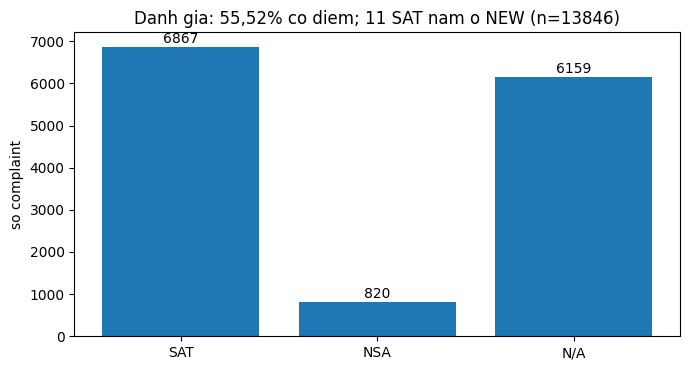

In [6]:
sbs = REP['sat_by_status']
sat_closed = sbs['CLOSED'].get('SAT', 0)
sat_new = sbs['NEW'].get('SAT', 0)
print(tab([['SAT CLOSED', sat_closed], ['SAT NEW', sat_new], ['SAT tong', sat_closed + sat_new],
           ['NSA tong', REP['sat_by_status']['CLOSED'].get('NSA', 0)],
           ['N/A tong', sum(d.get('N/A', 0) for d in sbs.values())],
           ['coverage %', round(100 * (sat_closed + sat_new + REP['sat_by_status']['CLOSED'].get('NSA', 0)) / N_COMPL, 2)]],
          ['chi_so', 'gia_tri']).to_string(index=False))
print(tab([[s, d.get('SAT', 0), d.get('NSA', 0), d.get('N/A', 0), sum(d.values())]
           for s, d in sorted(sbs.items(), key=lambda x: x[0])],
          ['status', 'SAT', 'NSA', 'N/A', 'tong']).to_string(index=False))
tot = [sat_closed + sat_new, sbs['CLOSED'].get('NSA', 0), sum(d.get('N/A', 0) for d in sbs.values())]
plt.figure(figsize=(7, 3.8))
plt.bar(['SAT', 'NSA', 'N/A'], tot)
for x, y in enumerate(tot):
    plt.text(x, y + 90, str(y), ha='center')
plt.title('Danh gia: 55,52%% co diem; 11 SAT nam o NEW (n=%d)' % N_COMPL)
plt.ylabel('so complaint'); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q05_satisfaction.png'), dpi=100)
plt.show()


**Quan sát:** SAT = **6.856 `CLOSED` + 11 `NEW` = 6.867**; 820 NSA; 6.159 `N/A`; coverage 55,52%. Đính chính rõ: **không phải "mọi complaint đang mở đều `N/A`"** — 11 ca `NEW` đã có điểm. Quy trình chấm **không chỉ xảy ra sau khi đóng**.

**Ý nghĩa:** tỷ lệ 89,33% phải luôn kèm coverage; mọi so sánh SAT theo phân khúc cần coverage của nhóm đó vì tỷ lệ đánh giá thay đổi theo thời điểm xử lý.

**Giới hạn:** chưa biết vì sao `NEW` được chấm sớm — dùng để lọc phân tích hay quy trình khác; cần người dùng xác nhận. **Phân loại:** số ✔ · nghĩa của `N/A` ✋ cần chốt.


## Q6 — 12.305 khách có phải insured base?

Câu hỏi gốc: mẫu số cho "complaint / 1.000 khách" có đúng không.

 Customers  co_complaint  khong_complaint  %_khong  complaint/1000_khach
     12305          8261             4044    32.86               1125.23


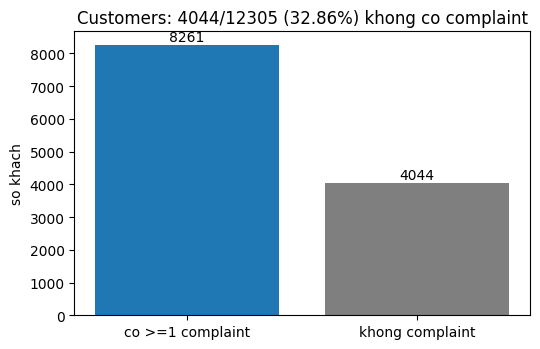

In [7]:
cu = REP['customers']
used_cust = {c['CustomerID'] for c in COMPL}
with_c = len({c['CustomerID'] for c in CUST} & used_cust)
without_c = len(CUST) - with_c
print(tab([[len(CUST), with_c, without_c, round(100 * without_c / len(CUST), 2),
           round(1000 * N_COMPL / len(CUST), 2)]],
          ['Customers', 'co_complaint', 'khong_complaint', '%_khong', 'complaint/1000_khach']).to_string(index=False))
plt.figure(figsize=(5.5, 3.6))
plt.bar(['co >=1 complaint', 'khong complaint'], [with_c, without_c], color=['tab:blue', 'tab:gray'])
for x, y in enumerate([with_c, without_c]):
    plt.text(x, y + 120, str(y), ha='center')
plt.title('Customers: %d/%d (%.2f%%) khong co complaint' % (without_c, len(CUST), 100 * without_c / len(CUST)))
plt.ylabel('so khach'); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q06_customer_coverage.png'), dpi=100)
plt.show()


**Quan sát (tính tại chỗ):** 12.305 khách; **8.261** có ≥1 complaint; **4.044 (32,86%)** không có. Tỷ lệ 1.125,23 complaint/1.000 khách.

**Ý nghĩa:** nhóm 4.044 không có complaint cho thấy bảng `Customers` rộng hơn tập khiếu nại — nhưng **chưa chứng minh là insured base**, vì không có bảng policy/hợp đồng.

**Giới hạn:** cần người dùng xác nhận nguồn `Customers`; nếu không có exposure thật, câu 5 và 9 của đề phải ghi giới hạn mẫu số. **Phân loại:** ~ một phần.


## Q7 — Reimbursement phân tích được gì với 13 quan sát?

Câu hỏi gốc: liên hệ giữa tiền kỳ vọng và satisfaction.

In [8]:
nz = [c for c in COMPL if isinstance(c['ExpectedReimbursement'], (int, float))
      and float(c['ExpectedReimbursement']) > 0]
amts = sorted((float(c['ExpectedReimbursement']) for c in nz), reverse=True)
total = round(sum(amts), 2)
print('so complaint co gia tri khac 0:', len(nz), '/', N_COMPL, '= %.2f%%' % (100 * len(nz) / N_COMPL))
print('tong tien:', total, '| min:', min(amts), '| max:', max(amts))
print('theo satisfaction:', dict(Counter(c['ClientSatisfaction'] for c in nz).most_common()))
print('theo status:', dict(Counter(STATUS[c['ComplainStatusID']] for c in nz).most_common()))
print('theo category:', dict(Counter(c['ComplainCategoryID'] for c in nz).most_common()))
print('top 3 gia tri chiem: %.2f%%' % (100 * sum(amts[:3]) / total))


so complaint co gia tri khac 0: 13 / 13846 = 0.09%
tong tien: 35379.26 | min: 14.37 | max: 15000.74
theo satisfaction: {'SAT': 7, 'N/A': 6}
theo status: {'CLOSED': 13}
theo category: {66.0: 6, 50.0: 3, 11.0: 2, 40.0: 1, 10.0: 1}
top 3 gia tri chiem: 70.66%


**Quan sát (chỉ tổng hợp, không xuất từng complaint):** **13/13.846 = 0,09%** có giá trị khác 0; tổng **35.379,26**; khoảng 14,37 → 15.000,74. Phân bố: **7 SAT / 6 `N/A` / 0 NSA**; toàn bộ 13 đều `CLOSED`; theo category tập trung 66 (6 ca) và 50 (3 ca); **3 giá trị lớn nhất chiếm 70,66% tổng**.

**Ý nghĩa:** 13 quan sát không đủ suy luận tương quan tiền–SAT; 3 giá trị chiếm 70% cho thấy trung bình không đại diện.

**Giới hạn:** cần currency, nghĩa của "expected" và cột đã chi trả (không có trong workbook). **Phân loại:** ~ mô tả được, phân tích sâu cần nguồn khác.


## Q8 — Tuổi nào dùng được cho phân tích nhân khẩu học?

Câu hỏi gốc: tuổi tại sự kiện và tỷ lệ Urgent theo nhóm.

    cohort tuoi     n
      >=18 tuoi 10438
      1-17 tuoi  2518
         tuoi 0   206
        tuoi am   491
thieu BirthDate   193
nhom >=18  Urgent  NonUrgent  Urgent_%
      <25      21        560      3.61
    25-34     125       2150      5.49
    35-44     157       3880      3.89
    45-54      74       2284      3.14
    55-64      26        973      2.60
      65+       1        187      0.53


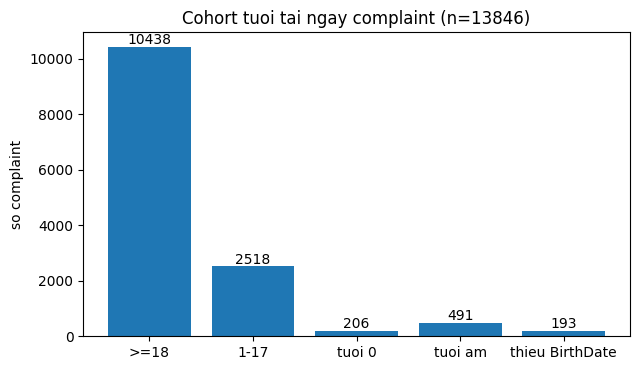

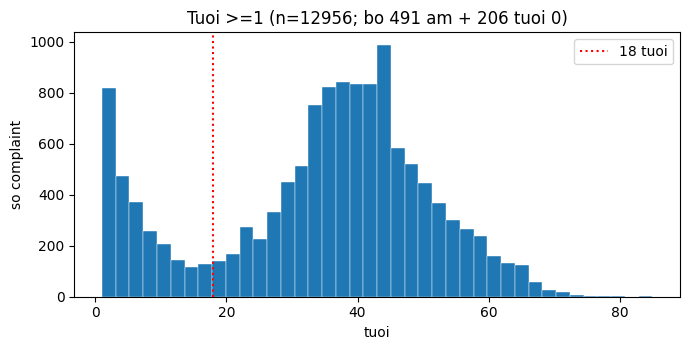

In [9]:
cohort = Counter()
band_u = Counter()
ages = []
for c in COMPL:
    b = BIRTH.get(c['CustomerID'])
    cd = c['ComplainDate']
    if not isinstance(b, (datetime, date)) or not isinstance(cd, (datetime, date)):
        cohort['thieu BirthDate'] += 1
        continue
    a = cd.year - b.year - ((cd.month, cd.day) < (b.month, b.day))
    if a < 0:
        cohort['tuoi am'] += 1
    elif a == 0:
        cohort['tuoi 0'] += 1
    elif a < 18:
        cohort['1-17 tuoi'] += 1
        ages.append(a)
    else:
        cohort['>=18 tuoi'] += 1
        ages.append(a)
        bb = '<25' if a < 25 else '25-34' if a < 35 else '35-44' if a < 45 else '45-54' if a < 55 else '55-64' if a < 65 else '65+'
        band_u[(bb, 'Urgent' if c['ComplainPriorityID'] == 1.0 else 'NonUrgent')] += 1
print(tab([[k, cohort[k]] for k in ['>=18 tuoi', '1-17 tuoi', 'tuoi 0', 'tuoi am', 'thieu BirthDate']],
          ['cohort tuoi', 'n']).to_string(index=False))
bands = ['<25', '25-34', '35-44', '45-54', '55-64', '65+']
print(tab([[b, band_u[(b, 'Urgent')], band_u[(b, 'NonUrgent')],
           round(100 * band_u[(b, 'Urgent')] / max(1, band_u[(b, 'Urgent')] + band_u[(b, 'NonUrgent')]), 2)]
           for b in bands], ['nhom >=18', 'Urgent', 'NonUrgent', 'Urgent_%']).to_string(index=False))
plt.figure(figsize=(6.5, 3.8))
keys = ['>=18 tuoi', '1-17 tuoi', 'tuoi 0', 'tuoi am', 'thieu BirthDate']
plt.bar([k.replace(' tuoi', '') for k in keys], [cohort[k] for k in keys])
for x, k in enumerate(keys):
    plt.text(x, cohort[k] + 90, str(cohort[k]), ha='center')
plt.title('Cohort tuoi tai ngay complaint (n=%d)' % N_COMPL)
plt.ylabel('so complaint'); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q08_age.png'), dpi=100)
plt.show()
plt.figure(figsize=(7, 3.6))
plt.hist(ages, bins=40, edgecolor='white', linewidth=0.3)
plt.axvline(18, color='red', linestyle=':', label='18 tuoi')
plt.title('Tuoi >=1 (n=%d; bo %d am + %d tuoi 0)' % (len(ages), cohort['tuoi am'], cohort['tuoi 0']))
plt.xlabel('tuoi'); plt.ylabel('so complaint'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q08_age_distribution.png'), dpi=100)
plt.show()


**Quan sát (tính tại chỗ từ record complaint và map `BIRTH` riêng):** **≥18 tuổi: 10.438**; 1–17 tuổi: 2.518; tuổi 0: 206; **tuổi âm: 491**; thiếu BirthDate: 193. Tổng ≥1 tuổi = 12.956. Bảng tỷ lệ Urgent chỉ tính trong nhóm ≥18.

**Ý nghĩa:** đính chính docs trước — 12.956 là cohort **≥1 tuổi**, không phải ≥18. Nhóm 1–17 tuổi là nhóm có thật, **không tự động coi là lỗi**; 491 tuổi âm mới là dấu hiệu dữ liệu không nhất quán.

**Giới hạn:** chưa biết 206 ca tuổi 0 và 2.518 ca 1–17 là lỗi nhập liệu hay khách vị thành niên đại diện — cần người dùng xác nhận. **Phân loại:** ~ một phần.


## Q9 — History ties và dwell nào đáng tin?

Câu hỏi gốc: thứ tự sự kiện, timestamp trùng, trạng thái cuối.

inter-event gap >0: n=5375 median=3.0 p90=14.0 max=142
trang thai tai cutoff (toan population)    n
                   co history <= cutoff 4351
                          thieu history 9495
                        latest xac dinh 3314
                       latest ambiguous 1037
ambiguity tren mau so CO HISTORY: 23.83% (1037/4351)
observed span first->last: giu 3539 de ve, bo 784


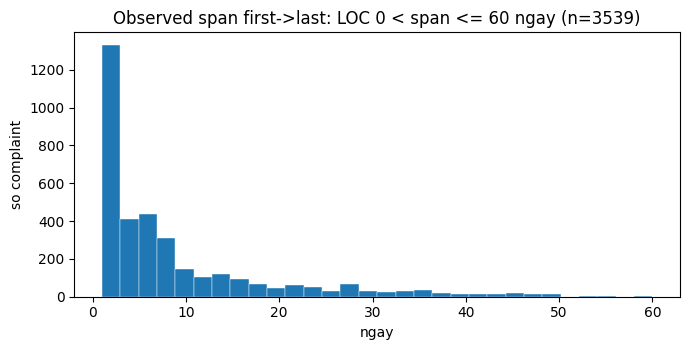

In [10]:
pg = PROF['status_history']['consecutive_dwell_days']
part = Counter(latest(c['ID'])[0] for c in COMPL)
n_with = len(EV)
print('inter-event gap >0: n=%d median=%s p90=%s max=%s' % (pg['n'], pg['median'], pg['p90'], pg['max']))
print(tab([['co history <= cutoff', n_with], ['thieu history', part['missing']],
           ['latest xac dinh', part['unambiguous']], ['latest ambiguous', part['ambiguous']]],
          ['trang thai tai cutoff (toan population)', 'n']).to_string(index=False))
print('ambiguity tren mau so CO HISTORY: %.2f%% (%d/%d)'
      % (100 * part['ambiguous'] / n_with, part['ambiguous'], n_with))
spans = [(EV[k][-1][0] - EV[k][0][0]).days for k in EV if len(EV[k]) > 1]
kept = [g for g in spans if 0 < g <= 60]
print('observed span first->last: giu %d de ve, bo %d' % (len(kept), len(spans) - len(kept)))
plt.figure(figsize=(7, 3.6))
plt.hist(kept, bins=30, edgecolor='white', linewidth=0.3)
plt.title('Observed span first->last: LOC 0 < span <= 60 ngay (n=%d)' % len(kept))
plt.xlabel('ngay'); plt.ylabel('so complaint'); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q09_dwell_span.png'), dpi=100)
plt.show()


**Quan sát:** trạng thái tại cutoff **trên toàn population**: 4.351 ca có history → **3.314 latest xác định**, **1.037 ambiguous**, **9.495 ca không có history**. Đây là số **quan sát ở cutoff**, không phải tái dựng trạng thái đã xác minh — chưa có quy tắc tie-break.

**Hai đại lượng khác nhau:** (a) **inter-event gap** — khoảng dương giữa hai event liên tiếp sau sort, n = 5.375, median 3 ngày, max 142; (b) **observed span** — khoảng event đầu đến event cuối, lọc `0 < span <= 60` còn 3.539 ca. Không đại lượng nào là **time-in-status**; **không có censoring nào được tính**.

**Giới hạn:** cần quy tắc tie-break và nguồn bổ sung để có dwell theo trạng thái; **presence coverage không chứng minh lịch sử đầy đủ**. **Phân loại:** ✔ số quan sát · ✋ quy tắc chưa chốt.


## Q10 — 4.044 khách không complaint có ý nghĩa gì?

Câu hỏi gốc: mẫu số Customers có đầy đủ insured base không.

In [11]:
per_c = Counter(c['CustomerID'] for c in COMPL)
with_c = len(set(per_c) & {c['CustomerID'] for c in CUST})
without_c = len(CUST) - with_c
print(tab([[without_c, with_c, round(100 * without_c / len(CUST), 2), len(per_c),
           min(per_c.values()), max(per_c.values()),
           round(sum(per_c.values()) / len(per_c), 2)]],
          ['khong_complaint', 'co_complaint', '%_khong', 'so_khach_co_complaint',
           'min_ca/khach', 'max_ca/khach', 'mean_ca/khach']).to_string(index=False))


 khong_complaint  co_complaint  %_khong  so_khach_co_complaint  min_ca/khach  max_ca/khach  mean_ca/khach
            4044          8261    32.86                   8261             1             8           1.68


**Quan sát (tính tại chỗ):** **4.044/12.305 = 32,86%** khách không gắn complaint; 8.261 khách có ít nhất một (trung bình 1,68; tối đa 8 complaint/khách).

**Ý nghĩa:** bảng rộng hơn tập khiếu nại, nhưng "không complaint" có thể là chưa khiếu nại / không còn hợp đồng / bản ghi thừa — không suy tỷ lệ rủi ro.

**Giới hạn:** cần nguồn policy/exposure. **Phân loại:** ✔ đếm · ✋ diễn giải.


## Q11 — AdministratorID dùng được không?

Câu hỏi gốc: ai xử lý, có đánh giá theo người được không.

AdministratorID    n
       num:98.0 7522
       num:16.0 3673
       num:42.0 1205
       num:85.0  785
       num:13.0  287
       str:NULL  172
       num:50.0  149
       num:81.0   52
       num:24.0    1
ma so: 8 | o chuoi NULL: 172 | tong complaint: 13846


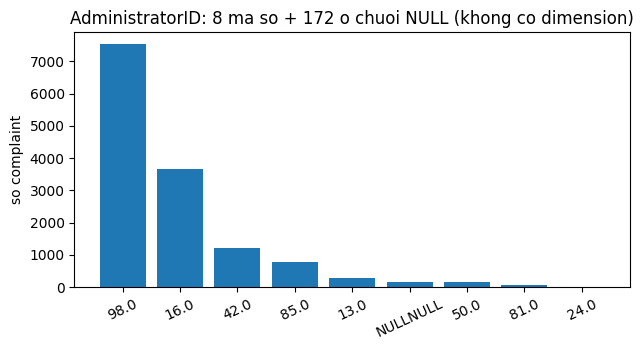

In [12]:
ad = INV['administrator_id_values']
num_codes = {k.replace('num:', '') for k in ad if k.startswith('num:')}
null_rows = sum(v for k, v in ad.items() if k.startswith('str:'))
print(tab(sorted(ad.items(), key=lambda x: -x[1]), ['AdministratorID', 'n']).to_string(index=False))
print('ma so:', len(num_codes), '| o chuoi NULL:', null_rows, '| tong complaint:', N_COMPL)
top = sorted(ad.items(), key=lambda x: -x[1])
plt.figure(figsize=(6.5, 3.6))
plt.bar([k.replace('num:', '').replace('str:', 'NULL') for k, _ in top], [v for _, v in top])
plt.title('AdministratorID: %d ma so + %d o chuoi NULL (khong co dimension)' % (len(num_codes), null_rows))
plt.ylabel('so complaint'); plt.xticks(rotation=25); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q11_admin.png'), dpi=100)
plt.show()


**Quan sát (đính chính: **8 mã số**, không phải 9):** 8 mã số (98: 7.522; 16: 3.673; 42: 1.205; 85: 785; 13: 287; 50: 149; 81: 52; 24: 1) cộng **172 ô chữ `"NULL"`**. Không có dimension Administrator.

**Ý nghĩa:** chỉ dùng như mã phân nhóm khối lượng; **không đánh giá cá nhân**. Hai mã đầu chiếm ~81% — tập trung hoá mạnh.

**Giới hạn:** cần danh mục nhân viên từ nguồn khác; 172 `"NULL"` xử lý cùng quy tắc Q1. **Phân loại:** ✔ mức mã · ✋ danh tính.


## Q12 — Category inactive có đang dùng không?

Câu hỏi gốc: có lọc category Active = 0 khi phân tích?

category inactive tu lookup: [5.0, 17.0, 20.0, 46.0, 47.0, 53.0, 54.0]
 so_category_inactive  complaint_dung_inactive  pct_tren_13846  so_id_da_dung
                    7                      158            1.14              5
 categoryID_inactive  n
                46.0 79
                54.0 58
                53.0 17
                47.0  3
                 5.0  1


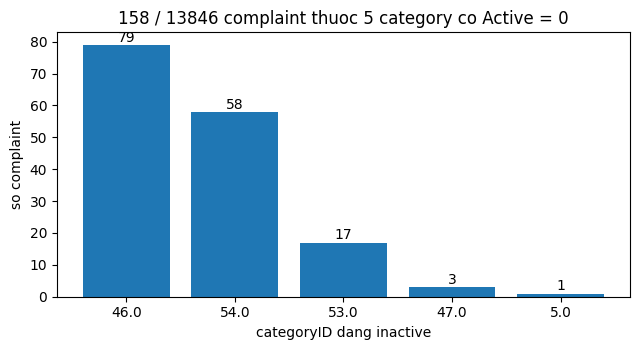

In [13]:
cats = named('Categories')
inact = {c['ID'] for c in cats if not blank(c.get('Active')) and float(c['Active']) == 0.0}
used = Counter(c['ComplainCategoryID'] for c in COMPL if c['ComplainCategoryID'] in inact)
print('category inactive tu lookup:', sorted(inact))
print(tab([[len(inact), sum(used.values()), round(100 * sum(used.values()) / N_COMPL, 2), len(used)]],
          ['so_category_inactive', 'complaint_dung_inactive', 'pct_tren_%d' % N_COMPL, 'so_id_da_dung']).to_string(index=False))
print(tab(sorted(used.items(), key=lambda x: -x[1]), ['categoryID_inactive', 'n']).to_string(index=False))
plt.figure(figsize=(6.5, 3.6))
us = sorted(used.items(), key=lambda x: -x[1])
plt.bar([str(k) for k, _ in us], [v for _, v in us])
for x, (_, v) in enumerate(us):
    plt.text(x, v + 1, str(v), ha='center')
plt.title('%d / %d complaint thuoc %d category co Active = 0' % (sum(used.values()), N_COMPL, len(used)))
plt.xlabel('categoryID dang inactive'); plt.ylabel('so complaint'); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q12_inactive.png'), dpi=100)
plt.show()


**Quan sát (ID lấy từ lookup `Categories.Active`, mẫu số = toàn bộ complaint):** 7 category inactive; **5 ID** thực sự dùng, gắn **158 / 13.846 = 1,14%** complaint; riêng 46 có 79 ca, 54 có 58 ca.

**Ý nghĩa:** lọc theo cờ `Active` sẽ xoá 158 ca. Cờ này là **hiện tại**, không có trường ngày hiệu lực nên **không chứng minh** dữ liệu lịch sử sai.

**Giới hạn:** cần người dùng chốt giữ hay lọc. **Phân loại:** ✔ đếm · ✋ quyết định.


## Q13 — History thiếu 68% thì journey làm được gì?

Câu hỏi gốc: độ phủ history có đủ cho bottleneck và backlog không.

      cohort  n (mau so)  co history <= cutoff  coverage_%  latest_ambiguous_n  ambiguous_%_cua_co_history
     toan bo       13846                  4351       31.42                1037                       23.83
      CLOSED       13796                  4301       31.18                1031                       23.97
nonclosed 50          50                    50      100.00                   6                       12.00
 21 muc tieu          21                    21      100.00                   4                       19.05

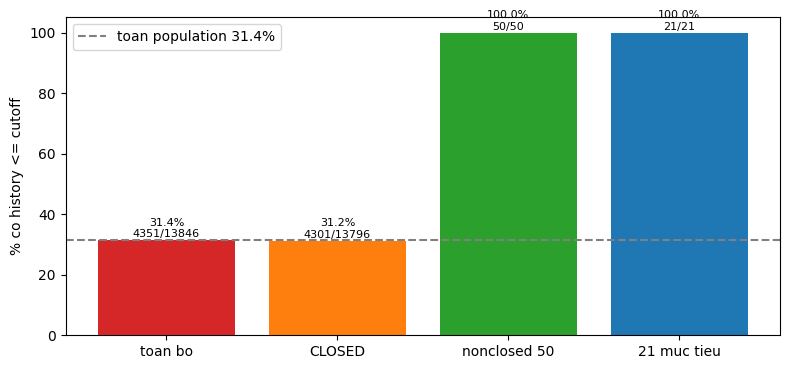

In [14]:
CLOSED = [c for c in COMPL if c['ComplainStatusID'] == 9.0]
NONC = [c for c in COMPL if c['ComplainStatusID'] != 9.0]
TGT = [c for c in COMPL if c['ComplainStatusID'] in (1.0, 3.0)]
rows = []
for name, grp in [('toan bo', COMPL), ('CLOSED', CLOSED), ('nonclosed 50', NONC), ('21 muc tieu', TGT)]:
    w = [c for c in grp if c['ID'] in EV]
    amb = sum(1 for c in w if latest(c['ID'])[0] == 'ambiguous')
    rows.append([name, len(grp), len(w), round(100 * len(w) / len(grp), 2), amb,
                 round(100 * amb / len(w), 2) if w else 0])
print(tab(rows, ['cohort', 'n (mau so)', 'co history <= cutoff', 'coverage_%',
                 'latest_ambiguous_n', 'ambiguous_%_cua_co_history']).to_string(index=False))
plt.figure(figsize=(8, 3.8))
lab = [r[0] for r in rows]
pc = [r[3] for r in rows]
x = range(len(lab))
plt.bar(list(x), pc, color=['tab:red', 'tab:orange', 'tab:green', 'tab:blue'])
for i, r in enumerate(rows):
    plt.text(i, r[3] + 1, '%.1f%%\n%d/%d' % (r[3], r[2], r[1]), ha='center', fontsize=8)
plt.axhline(100 * len(EV) / N_COMPL, color='gray', linestyle='--', label='toan population %.1f%%' % (100 * len(EV) / N_COMPL))
plt.xticks(list(x), lab)
plt.ylabel('% co history <= cutoff'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIG, 'q13_coverage.png'), dpi=100)
plt.show()


**Quan sát (mẫu số = TOÀN population của từng cohort):** toàn bộ **4.351/13.846 = 31,42%**; `CLOSED` **4.301/13.796 = 31,18%**; nonclosed **50/50 = 100%**; 21 mục tiêu 21/21. **Thiếu history: 9.495 ca.** Ambiguity tính trên **mẫu số riêng** (ca có history): toàn bộ 1.037/4.351 = 23,83%.

**Đính chính so với revision trước:** bảng cũ dùng denominator là cohort **đã lọc có history** nên mọi dòng đều 100%, làm ẩn 9.495 ca thiếu. Hình dạng đúng là nhóm nonclosed phủ 100% còn `CLOSED` chỉ ~31%.

**Ý nghĩa:** coverage 100% ở nhóm nonclosed **không chứng minh lịch sử đầy đủ** — nó chỉ nói các ca đó có event ≤ cutoff; 4.351 ca có history thì vẫn có 1.037 ca latest ambiguous. Journey mô tả được 4.351 ca với giới hạn, **không** phải toàn 13.846.

**Giới hạn:** chưa có tie-break, chưa tái dựng dwell theo trạng thái, chưa xử lý censoring. **Phân loại:** ✔ coverage · ✋ journey đầy đủ.


## Đối chiếu số quan trọng với nguồn đã kiểm

Cell dưới so **17 số do notebook tự tính** với số đã đối chiếu từ nguồn. Run hiện hành (C01–C03, xem `Log/phase1/RUNS.md` §17): check **56 PASS** exit 0, reconcile **17/17**, 0 error output, 12 ảnh inline. SAT và AdministratorID trong reconcile lấy từ aggregate đã đối chiếu, không phải mọi chỉ số đều tự tính trực tiếp trong notebook. Fail nghĩa là notebook lệch nguồn — không được diễn giải tiếp.

In [15]:
chk = []
chk.append(('complaints', N_COMPL, 13846))
chk.append(('SAT_closed', sat_closed, 6856))
chk.append(('SAT_new', sat_new, 11))
chk.append(('SAT_total', sat_closed + sat_new, 6867))
chk.append(('Q8_age_ge18', cohort['>=18 tuoi'], 10438))
chk.append(('Q8_age_1_17', cohort['1-17 tuoi'], 2518))
chk.append(('Q8_age_ge1', cohort['>=18 tuoi'] + cohort['1-17 tuoi'], 12956))
chk.append(('Q12_inactive_n', sum(used.values()), 158))
chk.append(('Q12_denominator', N_COMPL, 13846))
chk.append(('Q13_all_with_hist', len(EV), 4351))
chk.append(('Q13_missing', part['missing'], 9495))
chk.append(('Q13_ambiguous', part['ambiguous'], 1037))
chk.append(('Q13_nonclosed_cov', len([c for c in NONC if c['ID'] in EV]), 50))
chk.append(('Q13_closed_cov', len([c for c in CLOSED if c['ID'] in EV]), 4301))
chk.append(('customers_without', without_c, 4044))
chk.append(('reimb_total', total, 35379.26))
chk.append(('admin_codes', len(num_codes), 8))
bad = [c for c in chk if c[1] != c[2]]
for n, a, e in chk:
    print(('OK  ' if a == e else 'FAIL'), n, a, 'vs', e)
assert not bad, 'RECONCILE FAIL (notebook tu tinh lech aggregate): %s' % bad
print('reconcile OK: %d/%d so tu tinh trong notebook khop aggregate' % (len(chk), len(chk)))


OK   complaints 13846 vs 13846
OK   SAT_closed 6856 vs 6856
OK   SAT_new 11 vs 11
OK   SAT_total 6867 vs 6867
OK   Q8_age_ge18 10438 vs 10438
OK   Q8_age_1_17 2518 vs 2518
OK   Q8_age_ge1 12956 vs 12956
OK   Q12_inactive_n 158 vs 158
OK   Q12_denominator 13846 vs 13846
OK   Q13_all_with_hist 4351 vs 4351
OK   Q13_missing 9495 vs 9495
OK   Q13_ambiguous 1037 vs 1037
OK   Q13_nonclosed_cov 50 vs 50
OK   Q13_closed_cov 4301 vs 4301
OK   customers_without 4044 vs 4044
OK   reimb_total 35379.26 vs 35379.26
OK   admin_codes 8 vs 8
reconcile OK: 17/17 so tu tinh trong notebook khop aggregate


**Ý nghĩa:** cell này so **giá trị notebook tự tính** (`cohort`, `used`, `len(EV)`, `part`, `sat_closed`…) với số đã đối chiếu từ nguồn — không so hằng với chính aggregate. Đính chính B04: bản trước chỉ so `REP` với hằng nên vẫn in `PASS` dù 2 cell đang lỗi. Fail thì notebook lệch nguồn và **không được diễn giải tiếp**.

**Giới hạn:** đây là kiểm tra **17 số đã kiểm**, **không phải nghiệm thu toàn văn nội dung** và **không phải nghiệm thu KPI nghiệp vụ** — tie-break, as-of, dwell theo trạng thái và các quyết định nghiệp vụ vẫn chưa chốt.